# PCA baseline on the VAE SST data

This notebook applies principal component analysis (PCA) to **exactly the same monthly Pacific SST anomaly fields used by `VAE.ipynb`**. The crop, coarsening, anomaly calculation, chronological split, and train-only normalization are shared with the VAE pipeline.

PCA is a useful linear baseline for the convolutional VAE. It gives a compact representation with an unambiguous ordering of components and an exact linear reconstruction for a chosen number of components.

In [1]:
from __future__ import annotations

import csv
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.patches import Patch

from wk4proj.convvae_training import make_dataloaders, prepare_sst, set_seed

plt.rcParams["figure.dpi"] = 110
SEED = 42
N_COMPONENTS = 16  # Match the VAE latent dimension.
set_seed(SEED)

CATEGORY_COLOURS = {
    "VSE": "#85000f", "SE": "#85000f", "ME": "#ef3d3d",
    "WE": "#ef3d3d", "N": "#bdbdbd", "WL": "#7698e3",
    "ML": "#7698e3", "SL": "#022f8f", "VSL": "#022f8f",
}


## PCA implementation

The SVD is fitted on the first 80% of months only, matching the VAE's chronological training split. The remaining months are projected with the already-fitted PCA; they are not used to estimate the PCA mean or components. Missing SST cells are set to zero after applying the same train-fitted standardization as the VAE.

In [2]:
def fit_pca(training_matrix: np.ndarray, n_components: int) -> dict[str, np.ndarray]:
    """Fit PCA with SVD and return the mean, components, and variance diagnostics."""
    if training_matrix.ndim != 2:
        raise ValueError("training_matrix must be two-dimensional")
    if not 1 <= n_components <= min(training_matrix.shape):
        raise ValueError("n_components must not exceed either training dimension")
    mean = training_matrix.mean(axis=0)
    centered = training_matrix - mean
    _, singular_values, components = np.linalg.svd(centered, full_matrices=False)
    components = components[:n_components]
    explained_variance = singular_values[:n_components] ** 2 / (training_matrix.shape[0] - 1)
    total_variance = (singular_values**2).sum() / (training_matrix.shape[0] - 1)
    return {"mean": mean, "components": components, "explained_variance": explained_variance, "explained_variance_ratio": explained_variance / total_variance, "total_variance": np.array(total_variance)}


def project_pca(values: np.ndarray, pca: dict[str, np.ndarray]) -> np.ndarray:
    return (values - pca["mean"]) @ pca["components"].T


def reconstruct_pca(scores: np.ndarray, pca: dict[str, np.ndarray]) -> np.ndarray:
    return scores @ pca["components"] + pca["mean"]


## Prepare the shared VAE input

In [3]:
ds = xr.open_dataset("data/data.grib")
sst_anomaly = prepare_sst(ds)
_, _, standardizer, split = make_dataloaders(sst_anomaly, batch_size=16, validation_fraction=0.2, seed=SEED)

raw_values = np.asarray(sst_anomaly.values, dtype=np.float32)
normalized_values = standardizer.transform(raw_values)
normalized_values = np.nan_to_num(normalized_values, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

n_months, n_latitude, n_longitude = raw_values.shape
flat_values = normalized_values.reshape(n_months, -1)
train_values = flat_values[:split]
pca = fit_pca(train_values, N_COMPONENTS)
scores = project_pca(flat_values, pca)
reconstructed_normalized = reconstruct_pca(scores, pca)
reconstructed_anomaly = standardizer.inverse_transform(reconstructed_normalized.reshape(raw_values.shape))

print(f"Input fields: {n_months} months x {n_latitude} x {n_longitude} grid")
print(f"Chronological split: {split} train / {n_months - split} validation months")
print(f"PCA components: {N_COMPONENTS}")
print(f"Variance explained by first {N_COMPONENTS}: {pca['explained_variance_ratio'].sum():.2%}")


Input fields: 528 months x 256 x 256 grid
Chronological split: 422 train / 106 validation months
PCA components: 16
Variance explained by first 16: 59.90%


## Explained variance

The first plot shows how much training-set variance each component explains. The cumulative curve helps choose a compact PCA dimension independently of the VAE's chosen latent dimension.

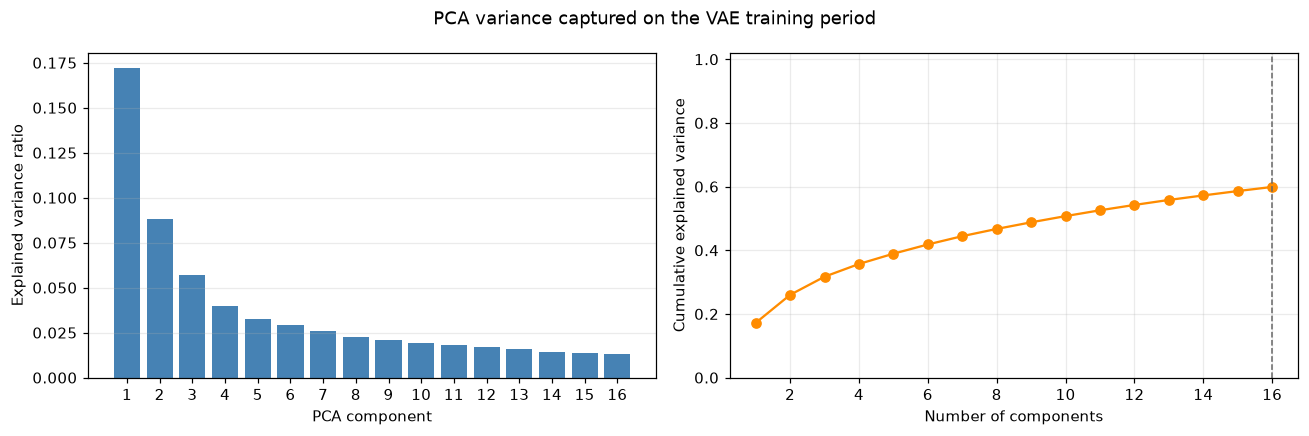

In [4]:
component_numbers = np.arange(1, N_COMPONENTS + 1)
ratios = pca["explained_variance_ratio"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(component_numbers, ratios, color="steelblue")
axes[0].set(xlabel="PCA component", ylabel="Explained variance ratio")
axes[0].set_xticks(component_numbers)
axes[0].grid(axis="y", alpha=0.25)
axes[1].plot(component_numbers, np.cumsum(ratios), marker="o", color="darkorange")
axes[1].axvline(N_COMPONENTS, color="0.4", linestyle="--", linewidth=1)
axes[1].set(xlabel="Number of components", ylabel="Cumulative explained variance")
axes[1].set_ylim(0, 1.02)
axes[1].grid(alpha=0.25)
fig.suptitle("PCA variance captured on the VAE training period")
fig.tight_layout()
plt.show()


## PCA score space coloured by ONI category

This is the PCA equivalent of the VAE latent-space plots. Unlike VAE coordinates, PCA components are ordered by explained variance and have a linear interpretation as spatial SST patterns.

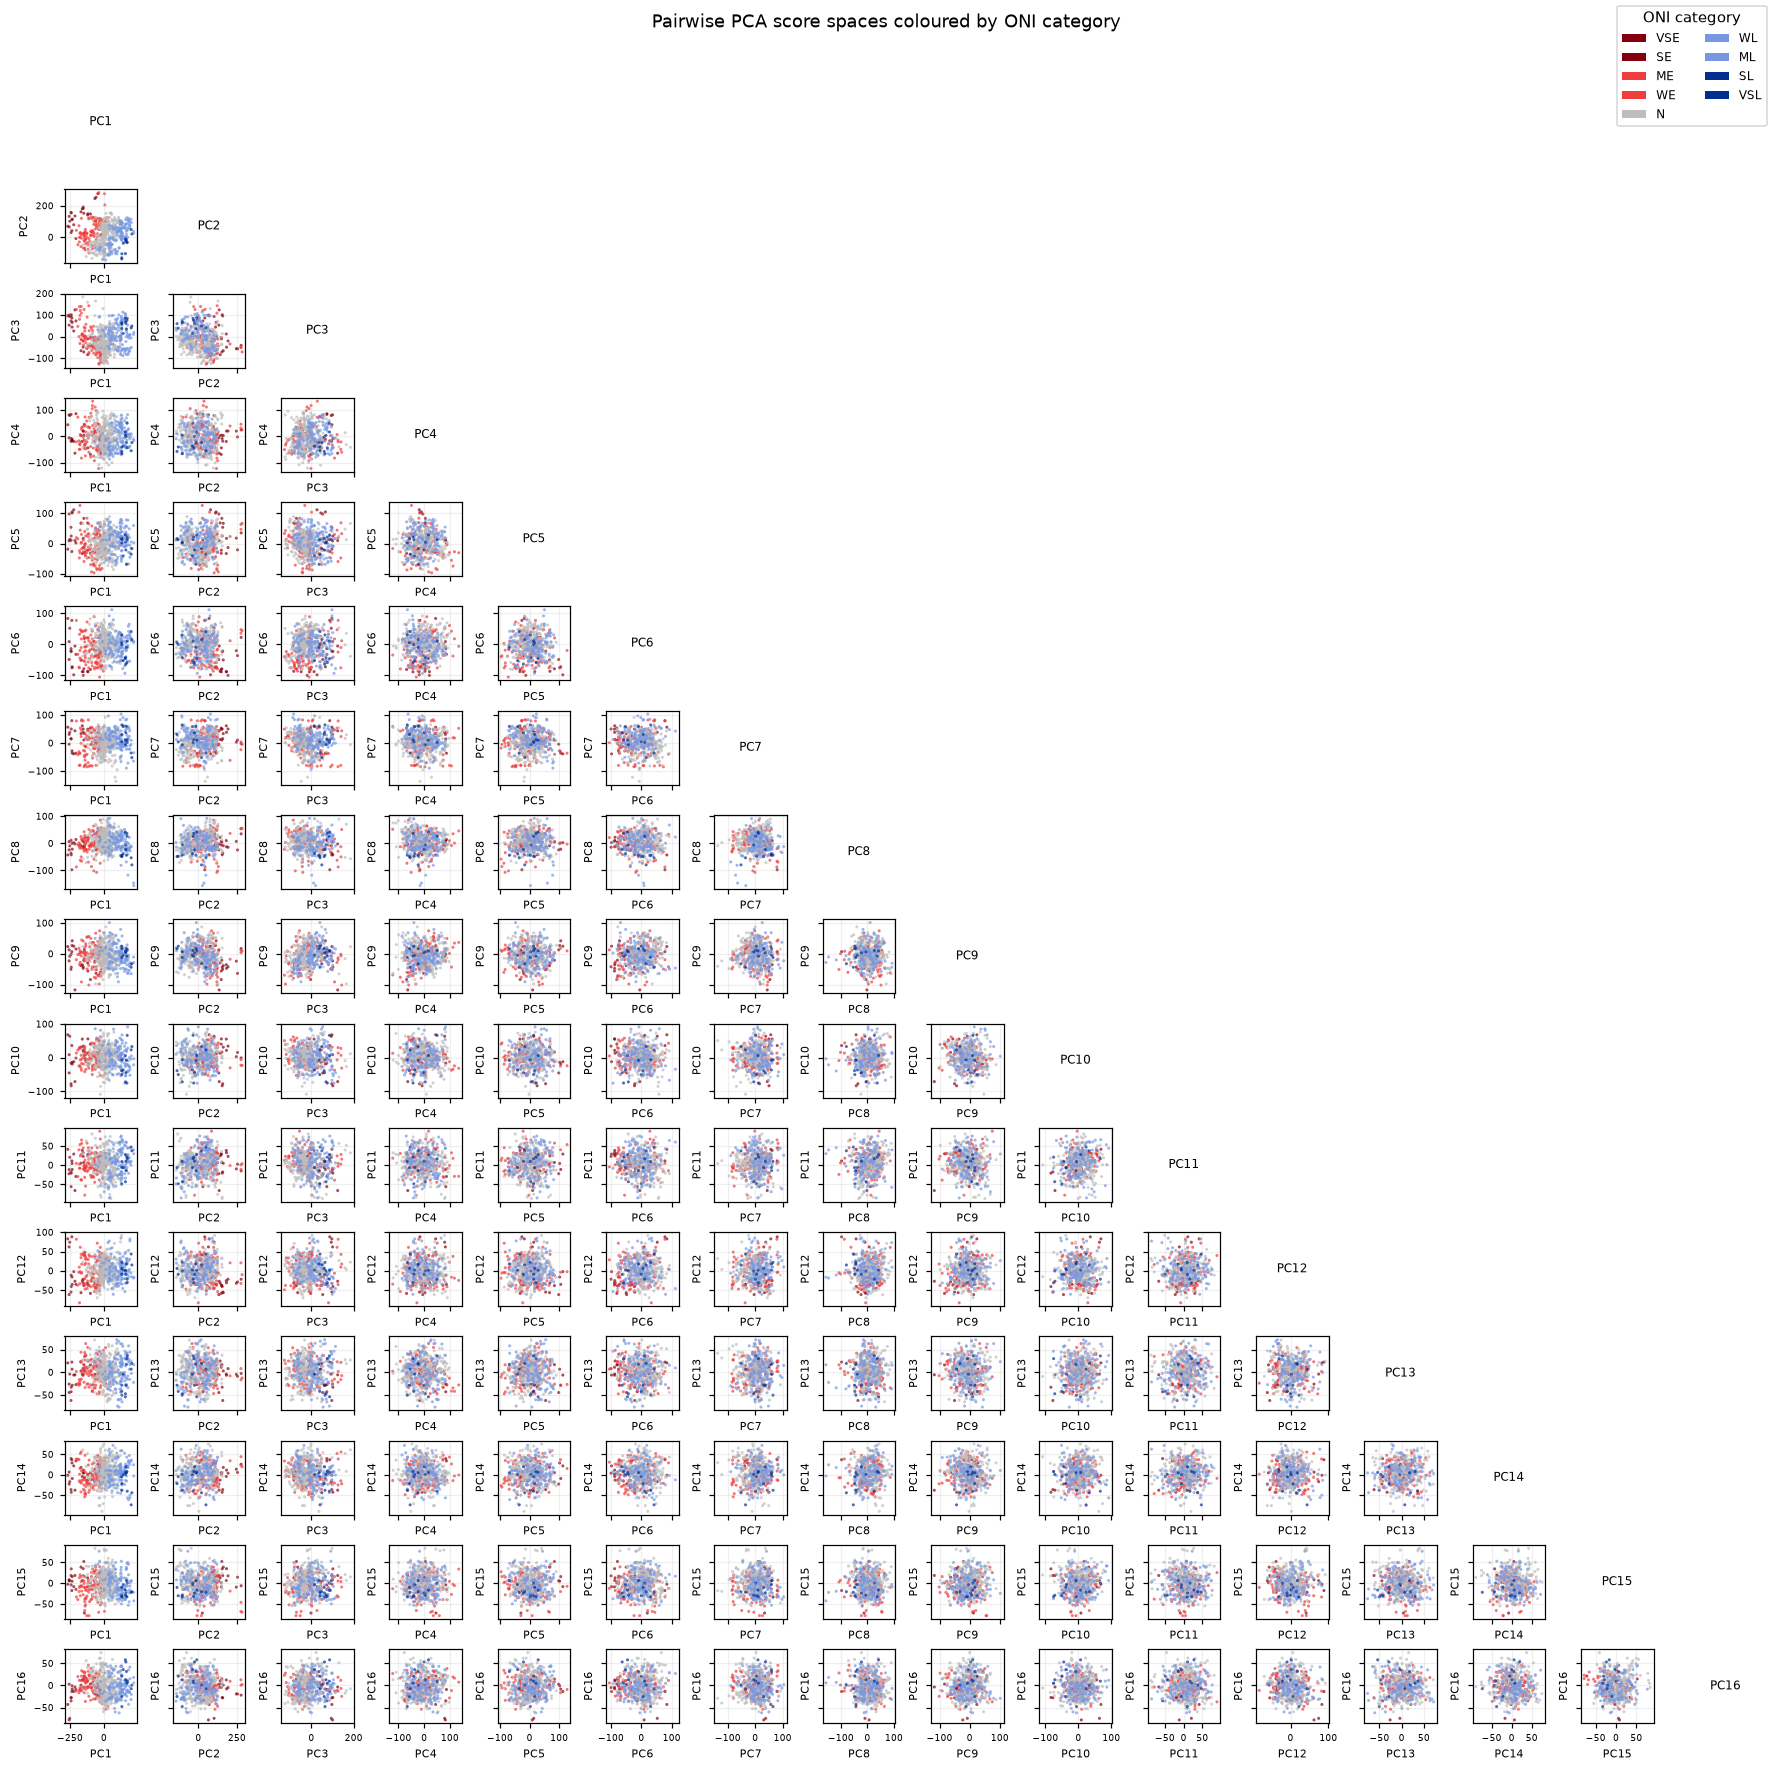

Matched 528 of 528 months to ONI categories


In [5]:
oni_by_date = {}
with Path("data/oni.csv").open(newline="") as oni_file:
    for row in csv.DictReader(oni_file):
        oni_by_date[row["date"]] = row["category"]

dates = sst_anomaly.time.dt.strftime("%Y-%m-%d").values
categories = np.array([oni_by_date.get(date, "Unlabelled") for date in dates])
matched = categories != "Unlabelled"

fig, axes = plt.subplots(N_COMPONENTS, N_COMPONENTS, figsize=(16, 16), sharex="col", sharey="row", squeeze=False)
for first, second in combinations(range(N_COMPONENTS), 2):
    axis = axes[second, first]
    for category, colour in CATEGORY_COLOURS.items():
        selected = matched & (categories == category)
        axis.scatter(scores[selected, first], scores[selected, second], color=colour, s=4, alpha=0.7, edgecolors="none", rasterized=True)
    axis.set_xlabel(f"PC{first + 1}", fontsize=7)
    axis.set_ylabel(f"PC{second + 1}", fontsize=7)
    axis.tick_params(labelsize=6)
    axis.grid(alpha=0.2)
for index in range(N_COMPONENTS):
    axes[index, index].text(0.5, 0.5, f"PC{index + 1}", ha="center", va="center", fontsize=8, transform=axes[index, index].transAxes)
    axes[index, index].set_axis_off()
for first in range(N_COMPONENTS):
    for second in range(first + 1, N_COMPONENTS):
        axes[first, second].set_visible(False)
fig.legend(handles=[Patch(facecolor=colour, label=category) for category, colour in CATEGORY_COLOURS.items()], title="ONI category", loc="upper right", ncol=2, fontsize=8)
fig.suptitle("Pairwise PCA score spaces coloured by ONI category", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97), pad=0.3)
plt.show()
print(f"Matched {matched.sum()} of {len(matched)} months to ONI categories")


## A directly comparable two-dimensional view

For a simple visual comparison, use the same two-dimensional view for both methods: PCA uses `PC1` and `PC2`; the VAE notebook can use its selected `z` pair. The axes are not expected to match numerically because PCA and VAE learn different coordinate systems.

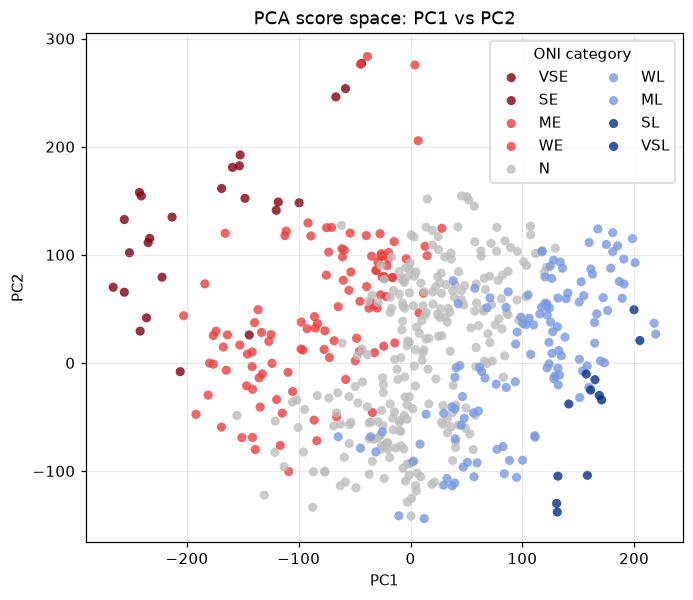

In [6]:
x_component, y_component = 0, 1
fig, axis = plt.subplots(figsize=(7, 6))
for category, colour in CATEGORY_COLOURS.items():
    selected = matched & (categories == category)
    axis.scatter(scores[selected, x_component], scores[selected, y_component], color=colour, label=category, alpha=0.8, edgecolors="none")
axis.set_xlabel(f"PC{x_component + 1}")
axis.set_ylabel(f"PC{y_component + 1}")
axis.set_title("PCA score space: PC1 vs PC2")
axis.legend(title="ONI category", ncol=2)
axis.grid(alpha=0.25)
plt.show()


## PCA reconstruction of one SST anomaly field

PCA reconstruction is the mean field plus a linear combination of the retained spatial components. This is comparable to the VAE decode panel, but PCA has no sampling step and no nonlinear decoder.

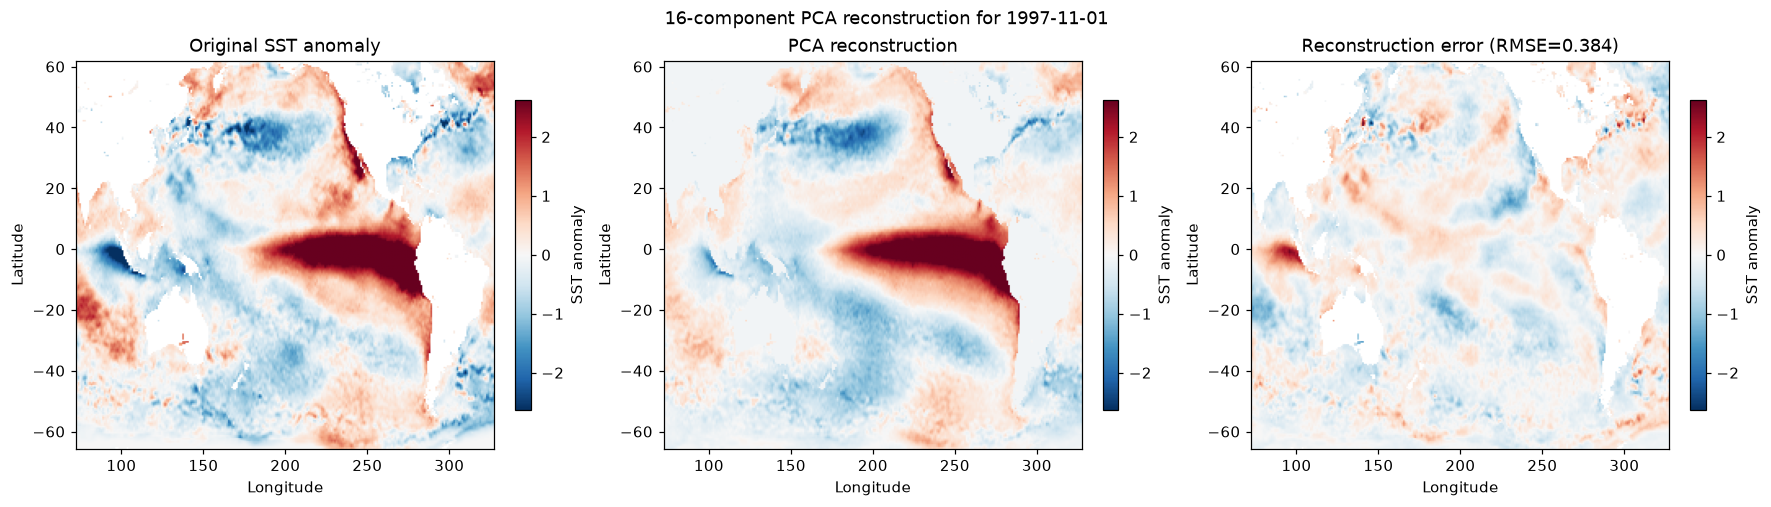

RMSE over finite ocean cells: 0.3838


In [7]:
sample_index = 214
if not 0 <= sample_index < n_months:
    raise ValueError(f"sample_index must be between 0 and {n_months - 1}")

original_anomaly = raw_values[sample_index]
reconstructed = reconstructed_anomaly[sample_index]
error = reconstructed - original_anomaly
valid = np.isfinite(original_anomaly)
rmse = float(np.sqrt(np.mean(error[valid] ** 2)))
date = str(sst_anomaly.time.isel(time=sample_index).values)[:10]

image_extent = [float(sst_anomaly.longitude.min()), float(sst_anomaly.longitude.max()), float(sst_anomaly.latitude.min()), float(sst_anomaly.latitude.max())]
plots = [(original_anomaly, "Original SST anomaly"), (reconstructed, "PCA reconstruction"), (error, f"Reconstruction error (RMSE={rmse:.3f})")]
common_limit = np.nanpercentile(np.concatenate([np.abs(image[valid]).ravel() for image, _ in plots]), 98)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for axis, (image, title) in zip(axes, plots):
    im = axis.imshow(image, origin="upper", extent=image_extent, cmap="RdBu_r", vmin=-common_limit, vmax=common_limit, aspect="auto")
    axis.set_title(title)
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")
    fig.colorbar(im, ax=axis, shrink=0.8, label="SST anomaly")
fig.suptitle(f"{N_COMPONENTS}-component PCA reconstruction for {date}")
plt.show()
print(f"RMSE over finite ocean cells: {rmse:.4f}")


## How to compare PCA and the VAE

Use a fixed experimental protocol rather than comparing the appearance of individual coordinates:

1. **Keep the data identical.** Use this notebook's `sst_anomaly`, chronological split, train-only normalization, finite-cell mask, and ONI date matching for both methods.
2. **Match representation size.** Start with 16 PCA components and the VAE's 16-dimensional latent vector. Also sweep several sizes (for example 2, 4, 8, 16, 32) to compare the trade-off fairly.
3. **Compare reconstruction quantitatively.** On the untouched validation months, calculate masked per-grid-cell RMSE and MAE in the original SST-anomaly units. Report mean and standard deviation across validation months. PCA's reconstruction is deterministic; use the VAE posterior mean for a deterministic comparison, as in `VAE.ipynb`.
4. **Compare spatial fidelity.** Inspect the same original/reconstruction/error panels and evaluate whether ENSO-related anomaly patterns are retained, not just the global error.
5. **Compare ENSO information.** Use the same ONI labels and either (a) a simple classifier trained on each representation using only the training period, evaluated on validation months, or (b) a label-separation metric. Do not choose VAE coordinates by looking at validation labels.
6. **Compare stability and cost.** Record training time, inference time, parameter count, and sensitivity to random seeds. PCA is linear, deterministic, and inexpensive after SVD; the VAE can model nonlinear structure but requires optimization and hyperparameter choices.

A useful summary table has one row per method and latent/component size, with validation RMSE, validation MAE, explained variance (PCA), ONI classification score, runtime, and seed variability. Lower reconstruction error is not automatically better if the representation loses the physically meaningful ENSO signal; report both reconstruction and downstream ONI performance.